<a href="https://colab.research.google.com/github/syifaymd/Pratikum-Analisis-Deret-Waktu/blob/main/Tugas_Kelompok_7_Minggu_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><center> PENDUGAAN PARAMETER </center></h1>
KELOMPOK 7 :

1. Nur Jannah Tuasikal (M0501251002)
2. Rismawati Saputri (A2502251012)
3. Syifa Ul Qalbi YMD (M0501251026)
4. Estyaningsi Purnama (M0501251058)

<center>
___________________________________________________________________________________________
</center>


<h1> TUGAS KELOMPOK </h1>
1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:

Kelompok 7: ARIMA (0,0,2) dan ARIMA (1,2,2)

<rjust> 2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh </rjust>

# Persiapan

In [1]:
!pip install rpy2

In [2]:
import warnings
warnings.filterwarnings("ignore")

#Jalankan syntax ini cukup satu kali, jangan berulang
%load_ext rpy2.ipython

In [3]:
%%R
install.packages('TSA')

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’, ‘leaps’, ‘locfit’, ‘tseries’

trying URL 'https://cran.rstudio.com/src/contrib/xts_0.14.3.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TTR_0.24.4.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quadprog_1.5-8.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/zoo_1.9-1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quantmod_0.4.29.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/leaps_3.2.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/locfit_1.5-9.12.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/tseries_0.10-63.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TSA_1.3.1.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpS8Sztb/downloaded_packages’


In [4]:
%%R
library(TSA)


Attaching package: ‘TSA’

The following objects are masked from ‘package:stats’:

    acf, arima

The following object is masked from ‘package:utils’:

    tar



# Soal 1. Simulasi dan Pendugaan Parameter
**Parameter dan ukuran contoh**

| Model | Parameter asli | n |
|---|---|---|
| ARIMA (0,0,2) | $\theta_1=0.4$, $\theta_2=-0.2$ | 100 |
| ARIMA (1,2,2) | $\phi_1=0.4$, $\theta_1=0.3$, $\theta_2=-0.2$ | 100 |

## Simulasi data

In [5]:
%%R

# Simulasi ARIMA (0,0,2)
set.seed(2598)
ma2 <- arima.sim(
  list(order = c(0,0,2),
       ma = c(0.4,-0.2)),
  n = 100
)

# Simulasi ARIMA (1,2,2)
# Bangkitkan ARMA(1,2), kemudian integrasikan dua kali
z <- arima.sim(
  list(order = c(1,0,2),
       ar = 0.4,
       ma = c(0.3,-0.2)),
  n = 100
)

arma122 <- cumsum(cumsum(as.numeric(z)))

# Menampilkan hasil simulasi
head(ma2)
head(arma122)


[1]  -0.7713949  -1.8760529  -4.3332709  -8.5458099 -15.8679703 -25.7793712


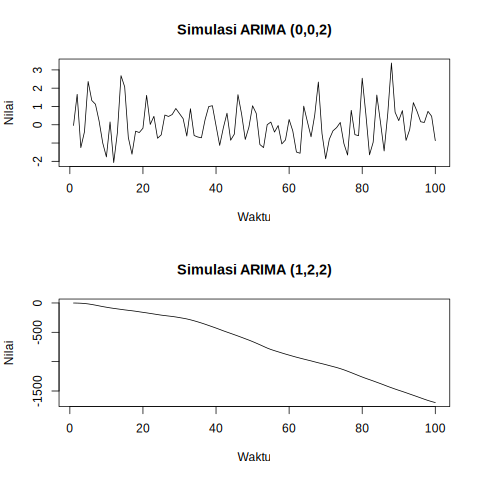

In [6]:
%%R

par(mfrow = c(2,1))

plot(ma2, type = "l",
     main = "Simulasi ARIMA (0,0,2)",
     xlab = "Waktu", ylab = "Nilai")

plot(arma122, type = "l",
     main = "Simulasi ARIMA (1,2,2)",
     xlab = "Waktu", ylab = "Nilai")

par(mfrow = c(1,1))

<h3> Metode Kuadrat Terkecil</h3>

Perhatikan model AR(1):

<center>$Y_t-\mu=\phi(Y_{t-1}-\mu)+e_t$</center>

Penduga kuadrat terkecil diperoleh dengan meminimalkan kuadrat dari jumlahan $(Y_t-\mu)-(\phi(Y_{t-1}-\mu)$, atau dapat dituliskan sebagai:

<center>$SSE=\sum_{i=1}^n [(Y_t-\mu)-(\phi(Y_{t-1}-\mu)]^2$</center>

Parameter 𝜙 dan 𝜇 diduga dengan nilai yang meminimalkan $SSE$ jika diberikan $𝑌_1, 𝑌_1, … , 𝑌_𝑛$. Bentuk ini dapat digeneralisasi untuk model AR(p). Penduga kuadrat terkecil dikenal juga dengan **penduga kuadrat terkecil bersyarat**.

Selanjutnya untuk model MA(1):

<center>$Y_t=e_t-\theta e_{t-1}$</center>

Jika kita perhatikan model di atas, mungkin tampak bahwa metode kudrat terkecil tidak bisa diaplikasikan pada model MA(1) tersebut. Ingat bahwa model MA (1) yang *invertible* dapat dinyatakan sebagai model autoregressive dengan order yang tidak berhingga:

<center>$Y_t=-\theta Y_{t-1}-\theta^2Y_{t-2}-\theta^3Y_{t-3}-...+e_t$</center>

Sehingga dengan cara yang sama dengan model AR di atas, penduga parameter dalam model MA dapat diduga dengan meminimalkan

<center>$SSE=\sum_{i=1}^n [Y_t+\theta Y_{t-1}+\theta^2Y_{t-2}+\theta^3Y_{t-3}+...]^2$</center>

Karena parameter dalam persamaan $SSE$ tersebut tidak linier, maka untuk meminimalkannya dapat dilakukan dengan optimisasi numerik (misalnya Newton Raphson).

<h3> Metode Kemungkinan Maksimum </h3>

Fungsi kemungkinan (*likelihood*) $𝐿$ didefinisikan sebagai fungsi kepekatan peluang bersama dari data yang diamati ($Y$). Fungsi likelihood merupakan fungsi atas parameter model yang tidak diketahui dan data yang teramati. Untuk model ARIMA, $𝐿$ merupakan fungsi atas $\phi,\theta,\mu$ dan $\sigma_e^2$ jika pengamatan $𝑌_1, 𝑌_2, … , 𝑌_𝑛$ diketahui. Penduga kemungkinan maksimum selanjutnya didefinisikan sebagai nilai-nilai parameter yang memaksimumkan fungsi likelihood.

## Pendugaan Parameter: ARIMA (0,0,2)


In [7]:
%%R
set.seed(2598)

# Simulasi data ARIMA(0,0,2)
ar1_1 <- arima.sim(
  model = list(order = c(0,0,2), ma = c(0.4,-0.2)),
  n = 100
)

# Pendugaan parameter dengan CSS
print(arima(ar1_1, order = c(0,0,2), method = "CSS"))

# Pendugaan parameter dengan ML
print(arima(ar1_1, order = c(0,0,2), method = "ML"))



Call:
arima(x = ar1_1, order = c(0, 0, 2), method = "CSS")

Coefficients:
         ma1      ma2  intercept
      0.2589  -0.3389     0.0366
s.e.  0.1002   0.0955     0.0878

sigma^2 estimated as 0.9041:  part log likelihood = -136.85

Call:
arima(x = ar1_1, order = c(0, 0, 2), method = "ML")

Coefficients:
         ma1      ma2  intercept
      0.2622  -0.3376     0.0377
s.e.  0.1006   0.0943     0.0880

sigma^2 estimated as 0.8974:  log likelihood = -136.69,  aic = 279.38


- Untuk data simulasi MA(2) menggunakan metode kuadrat terkecil (CSS), nilai parameter aslinya adalah 0.4 dan -0.2. Hasil penduga parameternya bernilai $0.2589$ dan $-0.3389$
- Untuk data simulasi MA(2) menggunakan metode ML (Maximum Likelihood), nilai parameter aslinya adalah 0.4 dan -0.2. Hasil penduga parameternya bernilai $0.2622$ dan $-0.3376$.

## Pendugaan Parameter: ARIMA (1,2,2)

In [8]:
%%R
set.seed(2598)

# Simulasi data untuk ARIMA(1,2,2)
z <- arima.sim(
  model = list(order = c(1,0,2), ar = 0.4, ma = c(0.3,-0.2)),
  n = 100
)

ar2_2 <- cumsum(cumsum(as.numeric(z)))

# Pendugaan parameter dengan CSS
print(arima(ar2_2, order = c(1,2,2),
            method = "CSS", transform.pars = FALSE))

# Pendugaan parameter dengan ML
print(arima(ar2_2, order = c(1,2,2),
            method = "ML", transform.pars = FALSE))



Call:
arima(x = ar2_2, order = c(1, 2, 2), transform.pars = FALSE, method = "CSS")

Coefficients:
         ar1      ma1      ma2
      0.6424  -0.0207  -0.4837
s.e.  0.3671   0.3513   0.2333

sigma^2 estimated as 0.8485:  part log likelihood = -131.01

Call:
arima(x = ar2_2, order = c(1, 2, 2), transform.pars = FALSE, method = "ML")

Coefficients:
         ar1      ma1      ma2
      0.9383  -0.3201  -0.6799
s.e.  0.0410   0.0865   0.0749

sigma^2 estimated as 0.8146:  log likelihood = -130.01,  aic = 266.01


- Untuk data simulasi ARIMA(1,2,2) menggunakan metode kuadrat terkecil (CSS), nilai parameter aslinya adalah 0.4 (untuk AR) serta 0.3 dan -0.2 (untuk MA). Hasil penduga parameternya bernilai $0.6424$ untuk AR (1), serta $-0.0207$ dan $-0.4837$ untuk MA (1) dan MA (2).   
- Untuk data simulasi ARIMA(1,2,2) menggunakan metode ML (Maximum Likelihood), nilai parameter aslinya adalah 0.4 (untuk AR) serta 0.3 dan -0.2 (untuk MA). Hasil penduga parameternya bernilai $0.9383$ untuk AR (1), serta $-0.3201$ dan $-0.6799$ untuk MA (1) dan MA (2).  

# Soal 2. Ulangan 30 Kali: Bias dan Ragam Penduga

Langkah Soal 1 diulang sebanyak 30 kali dijalankan sekali, lalu 30 deret dibangkitkan berurutan. Untuk setiap model, metode, dan parameter dihitung:

- **Bias** = rata-rata (penduga $-$ nilai asli)
- **Ragam** = ragam penduga dari 30 ulangan

In [9]:
%%R

set.seed(2598)

B <- 30
n <- 100

cat("Kelompok: 7\n")
cat("Seed:", 2598, "\n")
cat("Jumlah replikasi:", B, "\n")
cat("Jumlah observasi per simulasi:", n, "\n")


Kelompok: 7
Seed: 2598 
Jumlah replikasi: 30 
Jumlah observasi per simulasi: 100 


In [10]:
%%R

hasil <- data.frame()

for (b in 1:B) {

  # ====================================
  # MODEL 1: ARIMA (0,0,2)
  # ====================================

  y1 <- arima.sim(
    model = list(
      order = c(0,0,2),
      ma = c(0.4,-0.2)
    ),
    n = n
  )

  # ====================================
  # MODEL 2: ARIMA (1,2,2)
  # ====================================

  z <- arima.sim(
    model = list(
      order = c(1,0,2),
      ar = 0.4,
      ma = c(0.3,-0.2)
    ),
    n = n
  )

  y2 <- cumsum(cumsum(as.numeric(z)))

  # ====================================
  # ESTIMASI KEDUA MODEL
  # ====================================

  for (model in c("ARIMA(0,0,2)", "ARIMA(1,2,2)")) {

    if (model == "ARIMA(0,0,2)") {
      y <- y1
      orde <- c(0,0,2)
      nilai_benar <- c(ma1 = 0.4, ma2 = -0.2)
    } else {
      y <- y2
      orde <- c(1,2,2)
      nilai_benar <- c(ar1 = 0.4, ma1 = 0.3, ma2 = -0.2)
    }

    for (metode in c("CSS", "ML")) {

      fit <- tryCatch(
        suppressWarnings(
          arima(
            y,
            order = orde,
            method = metode,
            transform.pars = FALSE
          )
        ),
        error = function(e) NULL
      )

      if (!is.null(fit)) {

        koef <- fit$coef

        for (p in names(nilai_benar)) {

          if (p %in% names(koef)) {

            hasil <- rbind(
              hasil,
              data.frame(
                Replikasi = b,
                Model = model,
                Metode = metode,
                Parameter = p,
                Nilai_Benar = unname(nilai_benar[p]),
                Estimasi = unname(koef[p])
              )
            )
          }
        }
      }
    }
  }
}

cat("Jumlah baris estimasi yang berhasil:",
    nrow(hasil), "\n")

head(hasil, 10)

Jumlah baris estimasi yang berhasil: 300 
   Replikasi        Model Metode Parameter Nilai_Benar     Estimasi
1          1 ARIMA(0,0,2)    CSS       ma1         0.4  0.258861857
2          1 ARIMA(0,0,2)    CSS       ma2        -0.2 -0.338854178
3          1 ARIMA(0,0,2)     ML       ma1         0.4  0.262192949
4          1 ARIMA(0,0,2)     ML       ma2        -0.2 -0.337638236
5          1 ARIMA(1,2,2)    CSS       ar1         0.4  0.774842379
6          1 ARIMA(1,2,2)    CSS       ma1         0.3 -0.004489022
7          1 ARIMA(1,2,2)    CSS       ma2        -0.2 -0.465133866
8          1 ARIMA(1,2,2)     ML       ar1         0.4  0.675739220
9          1 ARIMA(1,2,2)     ML       ma1         0.3  0.128789338
10         1 ARIMA(1,2,2)     ML       ma2        -0.2 -0.344342784


In [11]:
%%R

# Memisahkan data berdasarkan model, metode,
# dan parameter yang diestimasi

kelompok <- split(
  hasil,
  interaction(
    hasil$Model,
    hasil$Metode,
    hasil$Parameter,
    drop = TRUE
  )
)

ringkasan <- do.call(
  rbind,
  lapply(kelompok, function(d) {

    data.frame(
      Model = d$Model[1],
      Metode = d$Metode[1],
      Parameter = d$Parameter[1],
      Jumlah_Estimasi = nrow(d),
      Rata_rata = mean(d$Estimasi),
      Bias = mean(d$Estimasi - d$Nilai_Benar),
      Ragam = var(d$Estimasi)
    )
  })
)

rownames(ringkasan) <- NULL

print(ringkasan)


          Model Metode Parameter Jumlah_Estimasi   Rata_rata         Bias
1  ARIMA(1,2,2)    CSS       ar1              30  0.36735461 -0.032645385
2  ARIMA(1,2,2)     ML       ar1              30  0.19391703 -0.206082972
3  ARIMA(0,0,2)    CSS       ma1              30  0.38767625 -0.012323754
4  ARIMA(1,2,2)    CSS       ma1              30  0.33585853  0.035858525
5  ARIMA(0,0,2)     ML       ma1              30  0.45414328  0.054143276
6  ARIMA(1,2,2)     ML       ma1              30  0.53198514  0.231985137
7  ARIMA(0,0,2)    CSS       ma2              30 -0.20540450 -0.005404497
8  ARIMA(1,2,2)    CSS       ma2              30 -0.20420549 -0.004205488
9  ARIMA(0,0,2)     ML       ma2              30 -0.22969218 -0.029692177
10 ARIMA(1,2,2)     ML       ma2              30 -0.07345811  0.126541887
        Ragam
1  0.23045445
2  0.36926020
3  0.01274630
4  0.23699642
5  0.04367940
6  0.39972199
7  0.01954849
8  0.11938400
9  0.02886984
10 0.20716422


## Boxplot
#### Boxplot Estimasi Parameter ARIMA, 30 Ulangan

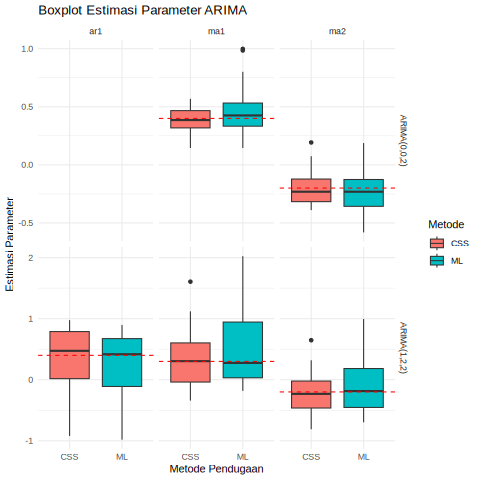

In [14]:
%%R

# Memeriksa package ggplot2
if (!requireNamespace("ggplot2", quietly = TRUE)) {
  install.packages("ggplot2")
}

library(ggplot2)

ggplot(
  hasil,
  aes(x = Metode, y = Estimasi, fill = Metode)
) +
  geom_boxplot() +
  geom_hline(
    aes(yintercept = Nilai_Benar),
    color = "red",
    linetype = "dashed"
  ) +
  facet_grid(
    Model ~ Parameter,
    scales = "free_y"
  ) +
  labs(
    title = "Boxplot Estimasi Parameter ARIMA",
    x = "Metode Pendugaan",
    y = "Estimasi Parameter"
  ) +
  theme_minimal()


- Model ARIMA(0,0,2):
  - Akurasi (Nilai Tengah): Nilai median (garis tebal di dalam kotak) dari hasil pendugaan parameter MA (1) dan MA (2) menggunakan metode Kuadrat Terkecil (CSS) dan metode Kemungkinan Maksimum (ML) berada sangat dekat dengan garis putus-putus merah. Hal ini menunjukkan bahwa kedua metode secara umum menghasilkan penduga yang mendekati nilai parameter sebenarnya.

  - Presisi (Sebaran Data): Sebaran data antara metode CSS dan ML relatif sebanding. Namun, metode ML (kotak berwarna biru) menunjukkan rentang antarkuartil yang sedikit lebih lebar dan memiliki titik pencilan (outlier) pada parameter MA (1) dan MA (2) dibandingkan metode CSS (kotak berwarna oren).

- Model ARIMA(1,2,2):
  - Akurasi (Nilai Tengah): Nilai median parameter AR (1), MA (1), dan MA (2) pada kedua metode secara umum mendekati nilai parameter sebenarnya yang ditunjukkan oleh garis putus-putus merah.

  - Presisi (Sebaran Data): Terlihat perbedaan variabilitas yang lebih mencolok. Kotak (rentang antarkuartil) dan garis vertikal (whisker) pada metode ML cenderung lebih lebar dan panjang dibandingkan metode CSS, terutama pada pendugaan parameter MA (1) dan AR (1). Hal ini mengindikasikan bahwa hasil estimasi metode ML memiliki variabilitas yang lebih besar atau kurang konsisten antarulangan dibandingkan metode CSS.

- Kesimpulan:
  Kedua metode secara umum menghasilkan dugaan yang mendekati nilai parameter sebenarnya. Namun, berdasarkan sebaran hasil estimasi dari 30 ulangan, metode Kuadrat Terkecil (CSS) tampak memberikan hasil estimasi yang lebih stabil dan konsisten, dengan variabilitas yang lebih kecil dibandingkan metode Kemungkinan Maksimum (ML). Perbedaan ini terutama terlihat pada model ARIMA(1,2,2), yang memiliki struktur parameter lebih kompleks.

#### Boxplot Bias Penduga Parameter

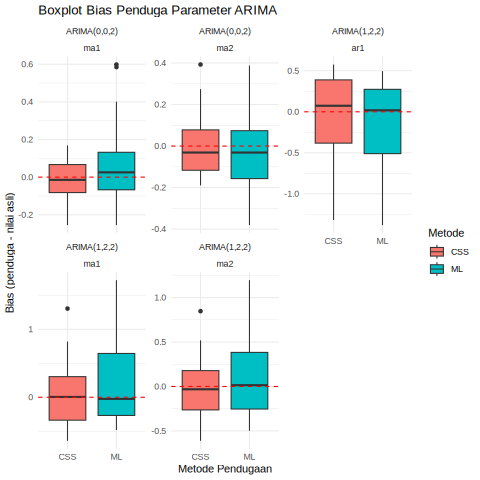

In [15]:
%%R
hasil$Bias <- hasil$Estimasi - hasil$Nilai_Benar

ggplot(hasil, aes(x = Metode, y = Bias, fill = Metode)) +
  geom_boxplot() +
  geom_hline(yintercept = 0, color = "red", linetype = "dashed") +
  facet_wrap(Model ~ Parameter, ncol = 3, scales = "free_y") +
  labs(title = "Boxplot Bias Penduga Parameter ARIMA",
       x = "Metode Pendugaan", y = "Bias (penduga - nilai asli)") +
  theme_minimal()

- Model ARIMA(0,0,2):
  - Akurasi (Nilai Tengah): Nilai median bias (garis tebal di dalam kotak) untuk parameter MA (1) dan MA (2) pada kedua metode, yaitu Kuadrat Terkecil (CSS) dan Kemungkinan Maksimum (ML), berada sangat dekat dengan angka 0 (garis putus-putus merah). Ini menunjukkan bahwa secara rata-rata, kedua metode menghasilkan penduga yang hampir tidak bias.

  - Presisi (Sebaran Data): Sebaran bias untuk metode CSS (kotak oren) dan ML (kotak biru) tampak serupa untuk MA (1) dan MA (2). Namun, metode ML menunjukkan rentang yang sedikit lebih lebar dan memiliki beberapa nilai pencilan (outlier) yang lebih ekstrem, terutama pada MA (1).

- Model ARIMA(1,2,2):
  - Akurasi (Nilai Tengah): Nilai median bias untuk parameter AR (1), MA (1), dan MA (2) pada kedua metode juga secara umum mendekati angka 0.

  - Presisi (Sebaran Data): Pada model yang lebih kompleks ini, terlihat bahwa rentang kotak (rentang antarkuartil) dan panjang garis vertikal (whisker) pada metode ML cenderung lebih besar dibandingkan metode CSS, terutama pada parameter MA (1) dan MA (2). Hal ini mengindikasikan bahwa hasil pendugaan dengan metode ML memiliki variabilitas bias yang lebih besar atau kurang presisi dibandingkan metode CSS pada simulasi ini.

Kesimpulan:
Secara umum, baik metode Kuadrat Terkecil (CSS) maupun metode Kemungkinan Maksimum (ML) mampu menghasilkan penduga parameter dengan bias yang relatif kecil, yaitu terpusat di sekitar angka 0. Akan tetapi, metode CSS menunjukkan variabilitas bias yang lebih kecil sehingga hasil pendugaannya cenderung lebih presisi dan stabil, terutama pada model ARIMA(1,2,2), dibandingkan metode ML yang memiliki rentang sebaran bias lebih lebar.

#### Ragam penduga dari 30 ulangan

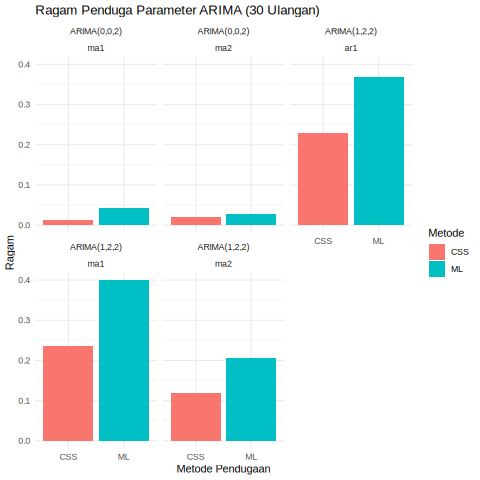

In [17]:
%%R
ggplot(ringkasan, aes(x = Metode, y = Ragam, fill = Metode)) +
  geom_col() +
  facet_wrap(Model ~ Parameter, ncol = 3) +
  labs(title = "Ragam Penduga Parameter ARIMA (30 Ulangan)",
       x = "Metode Pendugaan", y = "Ragam") +
  theme_minimal()

- Model ARIMA(0,0,2):
  - Nilai ragam untuk penduga parameter MA (1) dan MA (2) pada kedua metode tergolong sangat kecil atau mendekati angka 0.
  - Meskipun keduanya kecil, metode Kemungkinan Maksimum (ML) (batang berwarna biru) secara konsisten menunjukkan nilai ragam yang sedikit lebih tinggi dibandingkan metode Kuadrat Terkecil (CSS) (batang berwarna oren).

- Model ARIMA(1,2,2):
  - Pada model yang lebih kompleks ini, perbedaan ragam antara kedua metode terlihat jauh lebih signifikan.
  - Nilai ragam untuk penduga parameter AR (1), MA (1), dan MA (2) menggunakan metode ML secara konsisten lebih tinggi dibandingkan metode CSS. Sebagai contoh, ragam penduga MA (1) dengan metode ML mencapai sekitar 0.4, sedangkan metode CSS berada pada kisaran yang lebih rendah, yaitu sekitar 0.23.

Kesimpulan:
Secara keseluruhan, metode Kuadrat Terkecil (CSS) secara konsisten menghasilkan nilai ragam penduga yang lebih kecil dibandingkan metode Kemungkinan Maksimum (ML) pada seluruh parameter dan model yang disimulasikan. Hal ini mendukung temuan pada boxplot sebelumnya bahwa hasil pendugaan dengan metode CSS cenderung lebih stabil dan memiliki variabilitas yang lebih kecil antarulangan dibandingkan metode ML. Perbedaan ini terutama terlihat pada model dengan struktur yang lebih kompleks, yaitu ARIMA(1,2,2)